## Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, cross_val_score

# Doğrusal Regresyon (Linear Regression)

🎯 Bu egzersizde, bir NBA oyuncusunun win rating (`win_rating`) performansını, oynadığı dakika (`mp`) gibi maç istatistiklerine göre modelleyeceksiniz.


👉 [NBA.csv](https://d32aokrjazspmn.cloudfront.net/materials/NBA.csv) dataset’ini bu notebook’a bir pandas dataframe olarak yükleyin ve ilk 5 satırını görüntüleyin.

In [5]:
df = pd.read_csv('NBA.csv')

df.head()

,season,poss,mp,do_ratio,pacing,win_rating
0,1987,4847,2409,-1.546275,-0.599918,1.643091
1,2017,5582,2708,0.996587,0.531888,10.808427
2,2016,4976,2407,0.242598,0.127976,3.054773
3,2021,1178,585,-1.343806,-1.201034,0.230004
4,1988,4534,2056,-1.813990,-0.128997,0.905614


ℹ️ Dataset’in detaylı açıklamasını challenge README dosyasında bulabilirsiniz. Challenge boyunca buna mutlaka referans verin.


## 1. Özellik Setini ve Hedefi Tanımlayın (Define Feature Set and Target)

🎯 İlk hedef, oyuncuların akranlarına kıyasla genel performans puanı olan *Wins Above Replacement* (`win_rating`) değerini, oynadıkları dakika sayısına (`mp`) göre modellemektir.

👉 Bu iki değişkeni `X` ve `y` olarak atayın. `X`’in feature(lar), `y`’nin ise target olduğunu unutmayın.

In [6]:
import pandas as pd

# Veriyi yüklüyoruz
df = pd.read_csv('NBA.csv')

# 🎯 Hedef: win_rating değerini, oynanan dakika sayısına (mp) göre modellemek.
# X: Bağımsız değişken (Feature/Özellik) - scikit-learn için genellikle 2 boyutlu (DataFrame) beklenir.
X = df[['mp']] 

# y: Bağımlı değişken (Target/Hedef) - Tahmin edilecek değer (Series).
y = df['win_rating']

# Verilerimizi kontrol edelim
print("X (Dakika - Feature) İlk 5 Satır:")
print(X.head())
print("\ny (Win Rating - Target) İlk 5 Satır:")
print(y.head())

# Boyutları kontrol edelim (4000 satır veri olmalı)
print(f"\nX Boyutu: {X.shape}")
print(f"y Boyutu: {y.shape}")

X (Dakika - Feature) İlk 5 Satır:
     mp
0  2409
1  2708
2  2407
3   585
4  2056

y (Win Rating - Target) İlk 5 Satır:
0     1.643091
1    10.808427
2     3.054773
3     0.230004
4     0.905614
Name: win_rating, dtype: float64

X Boyutu: (4000, 1)
y Boyutu: (4000,)


👉 Bir scatter plot kullanarak rating ile oynanan dakika sayısı arasındaki ilişkiyi görselleştirin.

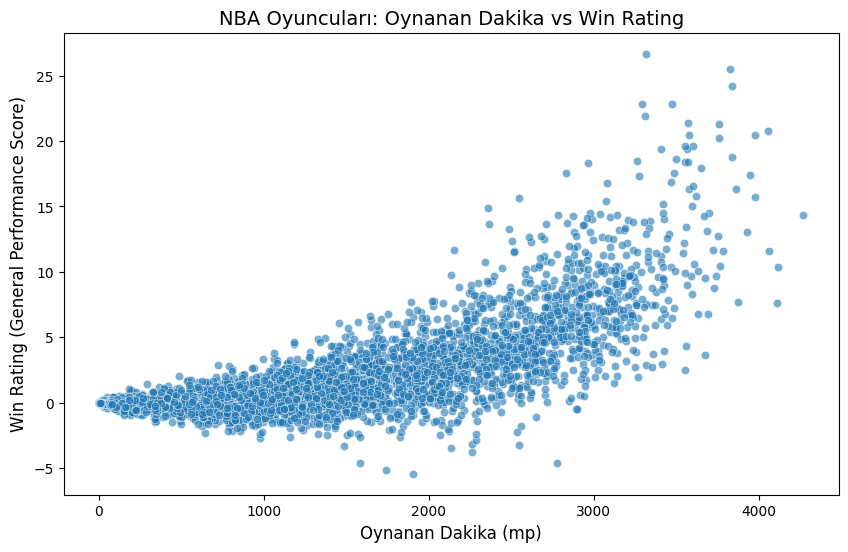

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot oluşturma
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='mp', y='win_rating', alpha=0.6)

# Grafik etiketleri
plt.title('NBA Oyuncuları: Oynanan Dakika vs Win Rating', fontsize=14)
plt.xlabel('Oynanan Dakika (mp)', fontsize=12)
plt.ylabel('Win Rating (General Performance Score)', fontsize=12)

plt.show()

ℹ️ Scatter plot, aralarında bir ilişki olduğunu düşündürmeli. Ancak bu ilişki tamamen doğrusal mı? 🤔 Göreceğiz!

## 2. Çapraz Doğrulama (Cross-Validation)

👉 Sklearn’in [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) fonksiyonunu kullanarak, oyuncu performans rating’ini oynanan dakika sayısına göre tahmin eden bir [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) modeli üzerinde 5-fold cross-validation çalıştırın. Cross-validation’ın ham çıktısını `cv_results` adlı yeni bir değişkende saklayın.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate

# Modelimizi tanımlayalım
model = LinearRegression()

# 5-fold cross-validation çalıştıralım
# Varsayılan olarak R^2 skorlarını döndürür
cv_results = cross_validate(model, X, y, cv=5)

# Ham çıktıyı görüntüleyelim
print(cv_results)

# Test skorlarının (R^2) ortalamasını alalım
print(f"Ortalama Test Skoru: {cv_results['test_score'].mean():.4f}")

{'fit_time': array([0.01995921, 0.00189805, 0.00185919, 0.00244164, 0.00873876]), 'score_time': array([0.00172782, 0.00134373, 0.00145531, 0.00179672, 0.00300932]), 'test_score': array([0.5555057 , 0.53447908, 0.53790391, 0.57658459, 0.57917762])}
Ortalama Test Skoru: 0.5567


❓ Cross-validation sonuçları içindeki en düşük skor nedir?  
Cevabınızı hesaplayın ve değeri `min_score` adlı yeni bir değişkende saklayın.

In [9]:
# Cross-validation sonuçları içindeki en düşük skoru hesaplayalım
min_score = cv_results['test_score'].min()

print(f"En düşük cross-validation skoru: {min_score}")

En düşük cross-validation skoru: 0.5344790822272503


❓ Cross-validation sonuçları içindeki en yüksek skor nedir?  
Cevabınızı hesaplayın ve değeri `max_score` adlı yeni bir değişkende saklayın.

In [10]:
# Cross-validation sonuçları içindeki en yüksek skoru hesaplayalım
max_score = cv_results['test_score'].max()

print(f"En yüksek cross-validation skoru: {max_score}")

En yüksek cross-validation skoru: 0.5791776193355004


❓ Cross-validation sonuçlarının ortalama skoru nedir?  
Cevabınızı hesaplayın ve değeri `mean_score` adlı yeni bir değişkende saklayın.

In [11]:
# Cross-validation sonuçları içindeki ortalama skoru hesaplayalım
mean_score = cv_results['test_score'].mean()

print(f"Ortalama cross-validation skoru: {mean_score}")

Ortalama cross-validation skoru: 0.556730180006891


ℹ️ Cross-validation çalıştırırken, model performansının en sağlam ve en temsil edici değerlendirmesi olarak her zaman ortalama skora bakarız.

### ☑️ Kodunu Test Et

In [12]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'cv_results',
    cv_result = cv_results,
    mean_score = mean_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/bariscan/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/bariscan/S16D1-S-data-linear-regression/tests
plugins: typeguard-4.4.2, anyio-4.8.0
collecting ... collected 2 items

test_cv_results.py::TestCvResults::test_cv_mean PASSED                   [ 50%]
test_cv_results.py::TestCvResults::test_cv_results PASSED                [100%]

============================== 2 passed in 1.95s ===============================


💯 You can commit your code:

git add tests/cv_results.pickle

git commit -m 'Completed cv_results step'

git push origin master



🤔 **Şimdi K-fold sayısının `K` (yani `cross_validate()` içindeki `cv` parametresi) etkisini inceleyelim**

👉 `K` değeri 2’den 20’ye çıkarken **<u>toplam</u> hesaplama süresinin (fit + score)** ve **<u>ortalama</u> skorun** nasıl değiştiğini plot edin.

<details>
  <summary markdown='span'><strong>İpucu</strong></summary>

  1. `K` değerlerini, hesaplama sürelerini ve cv ortalama skorlarını saklamak için 3 liste oluşturun.
  1. 2’den 20’ye kadar `K` değerleri üzerinde döngü kurun ve her seferinde:
     1. Cross-validation çalıştırın.
     1. `fit_time` ve `score_time` toplamını, toplam süreler listenize ekleyin.
     1. Ortalama `test_score` değerini, cv ortalama skorları listenize ekleyin.
  1. İki adet plot oluşturun:
     1. `K`’ye karşı toplam süre.
     1. `K`’ye karşı ortalama skor.
</details>


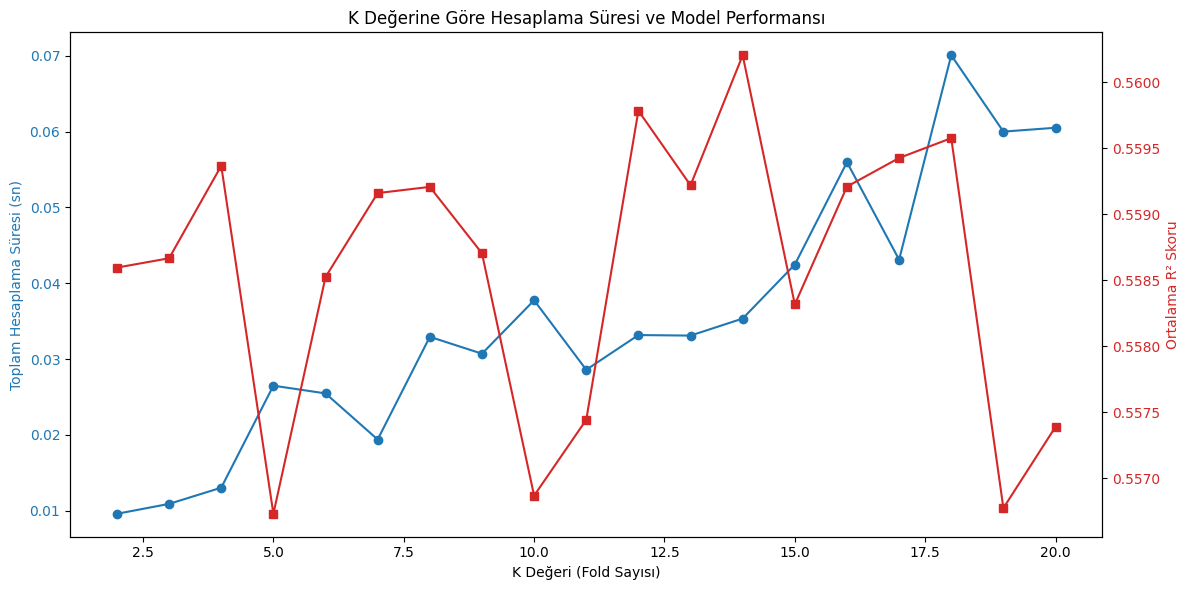

In [13]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression
import numpy as np

# Değişkenleri hazırlayalım
k_values = range(2, 21)
total_times = []
mean_scores = []

model = LinearRegression()

# K değerlerini döngüye sokalım
for k in k_values:
    # k-fold cross-validation çalıştır
    cv_res = cross_validate(model, X, y, cv=k)
    
    # Toplam hesaplama süresini hesapla (fit + score)
    total_time = np.sum(cv_res['fit_time']) + np.sum(cv_res['score_time'])
    total_times.append(total_time)
    
    # Ortalama skoru hesapla
    mean_scores.append(np.mean(cv_res['test_score']))

# Görselleştirme
fig, ax1 = plt.subplots(figsize=(12, 6))

# Sol eksen: Toplam Süre
color = 'tab:blue'
ax1.set_xlabel('K Değeri (Fold Sayısı)')
ax1.set_ylabel('Toplam Hesaplama Süresi (sn)', color=color)
ax1.plot(k_values, total_times, marker='o', color=color, label='Toplam Süre')
ax1.tick_params(axis='y', labelcolor=color)

# Sağ eksen: Ortalama Skor
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Ortalama R² Skoru', color=color)
ax2.plot(k_values, mean_scores, marker='s', color=color, label='Ortalama Skor')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K Değerine Göre Hesaplama Süresi ve Model Performansı')
fig.tight_layout()
plt.show()

ℹ️ $R^2$ skorunun sabit kaldığını görmelisiniz; bu, modelin hem daha küçük hem de daha büyük test setlerinde benzer performans gösterdiğinin iyi bir işaretidir. Buna karşılık, hesaplama süresi artmaya devam eder. Bu nedenle, pratik bir kural olarak genellikle K = 10’un üzerine çıkmayız.

## 3. Modeli eğit (Train the Model)

Cross-validation, veri seti üzerinde varsayımsal bir modeli değerlendirmek için kullanılır. Seçtiğiniz fold sayısı kadar modeli birden fazla kez eğitir; her seferinde verinin farklı bir alt kümesi üzerinde eğitilir ve kalan veriyle skor hesaplanır. Bu süreç bize, modelin ne kadar iyi performans gösterebileceğini gösteren cross-validated bir skor verir.

Ancak modeli gerçek anlamda tahmin yapmak için kullanmak istediğinizde, mümkün olduğunca fazla veriyle eğitmeyi tercih edersiniz. Yani verinin bir kısmını ayırmadan.

👉 Modeli, tam `X` ve `y` üzerinde eğitin (model skorunu zaten doğruladık, şimdi tahmin için kullanacağız). Eğitilmiş modeli `model` adlı değişkende saklayın.

In [14]:
from sklearn.linear_model import LinearRegression

# Modeli tanımlayalım
model = LinearRegression()

# Modeli tüm X ve y verileriyle eğitelim
model.fit(X, y)

print("Model başarıyla eğitildi ve 'model' değişkenine saklandı.")

Model başarıyla eğitildi ve 'model' değişkenine saklandı.


❓ Eğitilmiş modelinizin eğimi (slope) ya da katsayısı (coefficient) nedir?  
Bu değere modelin attribute’ları üzerinden erişebilirsiniz. Eğimi `slope` adlı bir değişkende saklayın.

In [17]:
# Modelin katsayısına (slope/coefficient) erişim
# Simple Linear Regression olduğu için ilk elemanı alıyoruz
slope = model.coef_[0]

print(f"Slope (Eğim): {slope}")

Slope (Eğim): 0.002602579938640193


❓ Eğitilmiş modelinizin intercept (sabit terim) değeri nedir?  
Bu değere modelin attribute’ları üzerinden erişebilirsiniz. Intercept değerini `intercept` adlı bir değişkende saklayın.

In [15]:
# Modelin intercept (sabit terim) değerine erişim
intercept = model.intercept_

print(f"Intercept: {intercept}")

Intercept: -1.5463749371639444


🤔 Devam etmeden önce bu katsayıları nasıl yorumlayacağınızı anladığınızdan emin olun.

### ☑️ Kodunu Test Et

In [18]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'trained_model',
    slope = slope,
    intercept = intercept
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/bariscan/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/bariscan/S16D1-S-data-linear-regression/tests
plugins: typeguard-4.4.2, anyio-4.8.0
collecting ... collected 2 items

test_trained_model.py::TestTrainedModel::test_intercept PASSED           [ 50%]
test_trained_model.py::TestTrainedModel::test_slope PASSED               [100%]

============================== 2 passed in 0.48s ===============================


💯 You can commit your code:

git add tests/trained_model.pickle

git commit -m 'Completed trained_model step'

git push origin master



## 4. Tahmin (Predict)

👉 Eğitilmiş modelinizi kullanarak toplamda 1000 dakika oynamış bir oyuncunun performans rating’ini tahmin edin.  
Tahmin edilen değeri `prediction` adlı bir değişkende saklayın.

In [19]:
import pandas as pd

# Tahmin etmek istediğimiz yeni veriyi hazırlayalım
# scikit-learn genellikle bir DataFrame veya 2B dizi bekler
new_data = pd.DataFrame({'mp': [1000]})

# Modeli kullanarak tahmini yapalım
# [0] kullanarak sonucun (array) içindeki tek değeri alıyoruz
prediction = model.predict(new_data)[0]

print(f"Tahmin Edilen Değer (1000 dakika): {prediction}")

Tahmin Edilen Değer (1000 dakika): 1.0562050014762487


### ☑️ Kodunu Test Et

In [20]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'prediction',
    prediction = prediction
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/bariscan/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/bariscan/S16D1-S-data-linear-regression/tests
plugins: typeguard-4.4.2, anyio-4.8.0
collecting ... collected 1 item

test_prediction.py::TestPrediction::test_prediction PASSED               [100%]

============================== 1 passed in 0.32s ===============================


💯 You can commit your code:

git add tests/prediction.pickle

git commit -m 'Completed prediction step'

git push origin master



## 5.  Daha Fazla Özellik ile Modeli İyileştirme (Improving the Model with More Features)

NBA fantasy league’i seven bir arkadaşınız size bazı içgörülerle geliyor 🏀

Bir oyuncunun *Wins Above Replacement* rating’ini değerlendirirken, genellikle topa sahip olma sayısına (`poss`), savunma/hücum oranına (`do_ratio`) ve `pacing` değerine de baktıklarını söylüyor.

❓ Aşağıdaki hücreyi çalıştırarak bu yeni feature’lar ile `win_rating` arasındaki korelasyonu görselleştirin.  
Yukarıdaki feature’lardan **hangisini** modelinize eklemeyi düşünürdünüz?

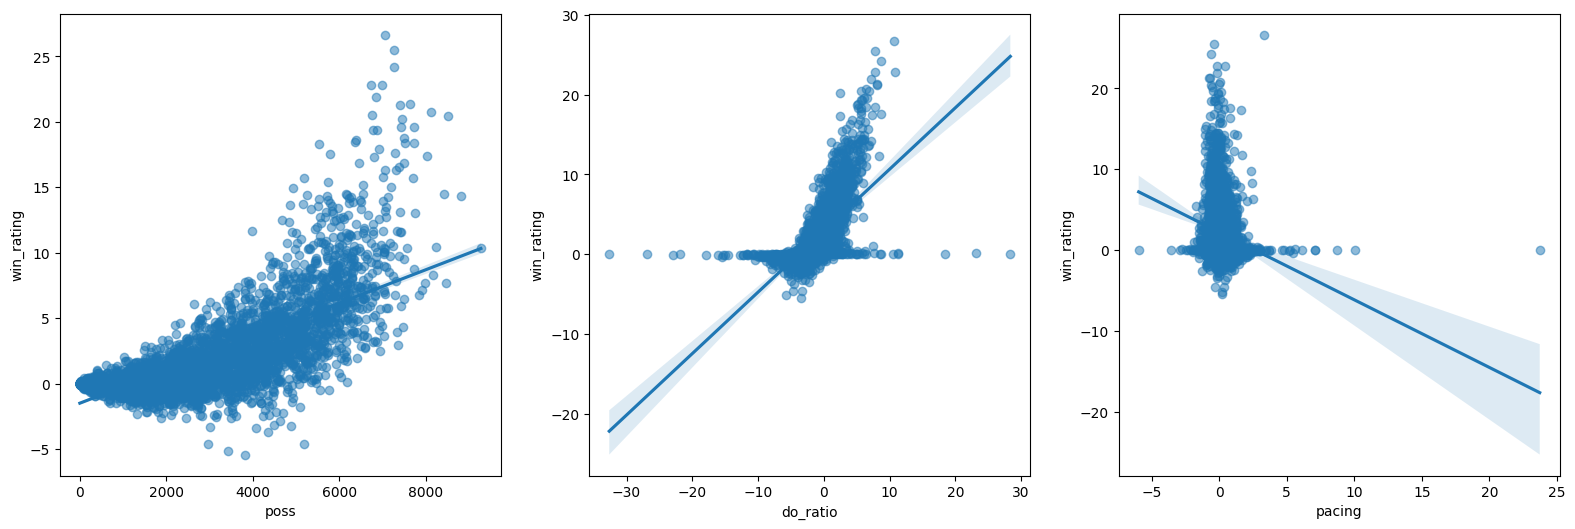

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 6))

plt.subplots_adjust(left=0.5, right=2)

sns.regplot(data=df, y='win_rating', x='poss', ax=axes[0], scatter_kws={'alpha':0.5})
sns.regplot(data=df, y='win_rating', x='do_ratio', ax=axes[1], scatter_kws={'alpha':0.5})
sns.regplot(data=df, y='win_rating', x='pacing', ax=axes[2], scatter_kws={'alpha':0.5})

plt.show()

<details>
  <summary markdown='span'><strong>Cevap</strong></summary>

  Feature’ları manuel olarak seçecek olsaydınız, hedef değişken olan `win_rating` ile en yüksek korelasyona sahip olanlarla başlardınız.

  Regresyon plot’larına baktığımızda, geriye `poss` ve `do_ratio` kalıyor. Sayısal değerleri görmek isterseniz `df.corr()[['win_rating']]` çıktısına bakabilirsiniz.

  Peki neden `poss` değil? Sonuçta `win_rating` ile olan korelasyonu `do_ratio`’dan daha yüksek.

  Bir de şuna bakın: `sns.scatterplot(data=df, x='mp', y='poss');`. Nedenini görebiliyor musunuz?

  <details>
  <summary><strong>Cevap</strong></summary>

  Görünen o ki, ilk feature’ımız olan `mp` ile `poss` neredeyse mükemmele yakın şekilde korelasyonlu. Bu yüzden `poss`, modele çok az ek değer katacaktır.

  </details>

</details>

Şimdi, iki feature kullanan modelin (seçtiğiniz yeni feature ve `mp`) bir oyuncunun rating’ini tahmin etmede ilk modelimizden daha iyi olup olmadığına bakalım.

👉 İki sütunlu bir DataFrame olacak şekilde yeni bir feature set’i oluşturun.

In [22]:
# 1. Yeni feature set'imizi seçiyoruz: 'mp' ve 'poss'
# (Analizimize göre poss, mp'den sonra win_rating ile en yüksek korelasyona sahip değişken)
X2 = df[['mp', 'poss']]

# 2. X2'nin ilk birkaç satırını ve yapısını kontrol edelim
print("Yeni Feature Set (X2) İlk 5 Satır:")
print(X2.head())

print(f"\nX2 Boyutu: {X2.shape}")

Yeni Feature Set (X2) İlk 5 Satır:
     mp  poss
0  2409  4847
1  2708  5582
2  2407  4976
3   585  1178
4  2056  4534

X2 Boyutu: (4000, 2)


👉 Şimdi yeni bir linear regression modeli için cross-validation çalıştırın ve **ortalama** skoru `mean_2_feat_score` değişkenine kaydedin.

> Not: Eğer sadece cross-validation skoruyla ilgileniyorsanız (hesaplama süreleriyle değil), sklearn’in [`cross_val_score`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) fonksiyonunu kullanabilirsiniz.

In [25]:
# 'mp' yanına 'do_ratio' ekliyoruz
X2 = df[['mp', 'do_ratio']]

# 5-fold cross-validation'ı tekrar çalıştıralım
scores_2_feat = cross_val_score(LinearRegression(), X2, y, cv=5)
mean_2_feat_score = scores_2_feat.mean()

print(f"Yeni (mp + do_ratio) Modeli Ortalama Skoru: {mean_2_feat_score:.4f}")

Yeni (mp + do_ratio) Modeli Ortalama Skoru: 0.6318


### ☑️ Kodunu Test Et

In [26]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'improved_score',
    improved_score = mean_2_feat_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/bariscan/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/bariscan/S16D1-S-data-linear-regression/tests
plugins: typeguard-4.4.2, anyio-4.8.0
collecting ... collected 1 item

test_improved_score.py::TestImprovedScore::test_improved_score PASSED    [100%]

============================== 1 passed in 0.28s ===============================


💯 You can commit your code:

git add tests/improved_score.pickle

git commit -m 'Completed improved_score step'

git push origin master



$R^2$ değerinizde **yaklaşık %8’lik bir artış** görmelisiniz 👏

Tebrikler, ilk manuel *feature selection* işleminizi gerçekleştirdiniz — bu hafta bunun daha birçok yolunu göreceğiz!

🤔 Peki Linear Regression ile yapabileceğimiz en iyi şey bu mu? Bir sonraki challenge’da bunu daha derinlemesine keşfedelim!

# 🏁